<a href="https://colab.research.google.com/github/tamarajovicic1/Data-Science-Masters/blob/main/heart-disease-prediction/heart_disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Opis problema i cilj analize:**

Ovaj projekat analizira podatke o srčanim bolestima kako bi razvio model za predikciju prisustva srčane bolesti na osnovu medicinskih parametara pacijenata.

Ciljevi analize su:

*   Istražiti i vizualizovati distribuciju podataka.
*   Pripremiti podatke i napraviti normalizaciju numeričkih vrednosti.
*   Primeniti različite metode mašinskog učenja (logistička regresija, Random Forest i još neke) kako bi se predvidelo u više različitih primera da li pacijent ima srčanu bolest.
*   Uporediti performanse modela i analizirati koji model daje najbolje rezultate.

# **2. Opis modela podataka: atributi, tipovi i domeni:**

In [ ]:
import pandas as pd

df = pd.read_csv('heart (1).csv')

In [ ]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [ ]:
print(df.columns)

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')


In [ ]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


Provera nedostajućih vrednosti:

In [ ]:
missing_values = df.isnull().sum()

In [ ]:
target_distribution = df["HeartDisease"].value_counts(normalize=True)

In [ ]:
#Korelacije između osobina i HeartDisease(ako je blizu +1 velika povezanost)
correlation_matrix = df.corr(numeric_only=True)

missing_values, target_distribution, correlation_matrix

(Age               0
 Sex               0
 ChestPainType     0
 RestingBP         0
 Cholesterol       0
 FastingBS         0
 RestingECG        0
 MaxHR             0
 ExerciseAngina    0
 Oldpeak           0
 ST_Slope          0
 HeartDisease      0
 dtype: int64,
 HeartDisease
 1    0.553377
 0    0.446623
 Name: proportion, dtype: float64,
                    Age  RestingBP  Cholesterol  FastingBS     MaxHR   Oldpeak  \
 Age           1.000000   0.254399    -0.095282   0.198039 -0.382045  0.258612   
 RestingBP     0.254399   1.000000     0.100893   0.070193 -0.112135  0.164803   
 Cholesterol  -0.095282   0.100893     1.000000  -0.260974  0.235792  0.050148   
 FastingBS     0.198039   0.070193    -0.260974   1.000000 -0.131438  0.052698   
 MaxHR        -0.382045  -0.112135     0.235792  -0.131438  1.000000 -0.160691   
 Oldpeak       0.258612   0.164803     0.050148   0.052698 -0.160691  1.000000   
 HeartDisease  0.282039   0.107589    -0.232741   0.267291 -0.400421  0.403951  

# **3. Vizualizacija (deskripcija) početnih ulaznih podataka: distribucije atributa po tipovima:**


U prikazanom histogramu imena tabela su malo komplikovanija za razumeti. U nastavku je opisano šta znači ime svake kolone:


---


*   Age (Godine) – numerički atribut
*   Sex (Pol) – kategorijski atribut (Male/Female)
*   ChestPainType (Tip bola u grudima) – kategorijski atribut (ATA - Atipičan bol, NAP - normalan bol, ASY - ne pojavljuje se bol, TA - Tipična angina)
*   RestingBP (Krvni pritisak u mirovanju) – numerički atribut
*   Cholesterol (Nivo holesterola) – numerički atribut
*   FastingBS (Šećer u krvi natašte) – binarni atribut (0 ili 1)
*   RestingECG (Rezultat elektrokardiograma) – kategorijski atribut (Normal, LVH - Left Ventricular Hypertrophy, ST - ST-T Wave Abnormality)
*   MaxHR (Maksimalni otkucaji srca) – numerički atribut
*   ExerciseAngina (Angina prilikom vežbanja) – binarni atribut (Yes/No)
*   Oldpeak (Depresija ST segmenta) – numerički atribut
*   ST_Slope (Nagib ST segmenta) – kategorijski atribut (Flat, Up, Down)
*   HeartDisease (Prisustvo srčane bolesti) – binarni atribut (0 ili 1)
















Radi još malo lakšeg prikaza podataka kreiraću histogram:

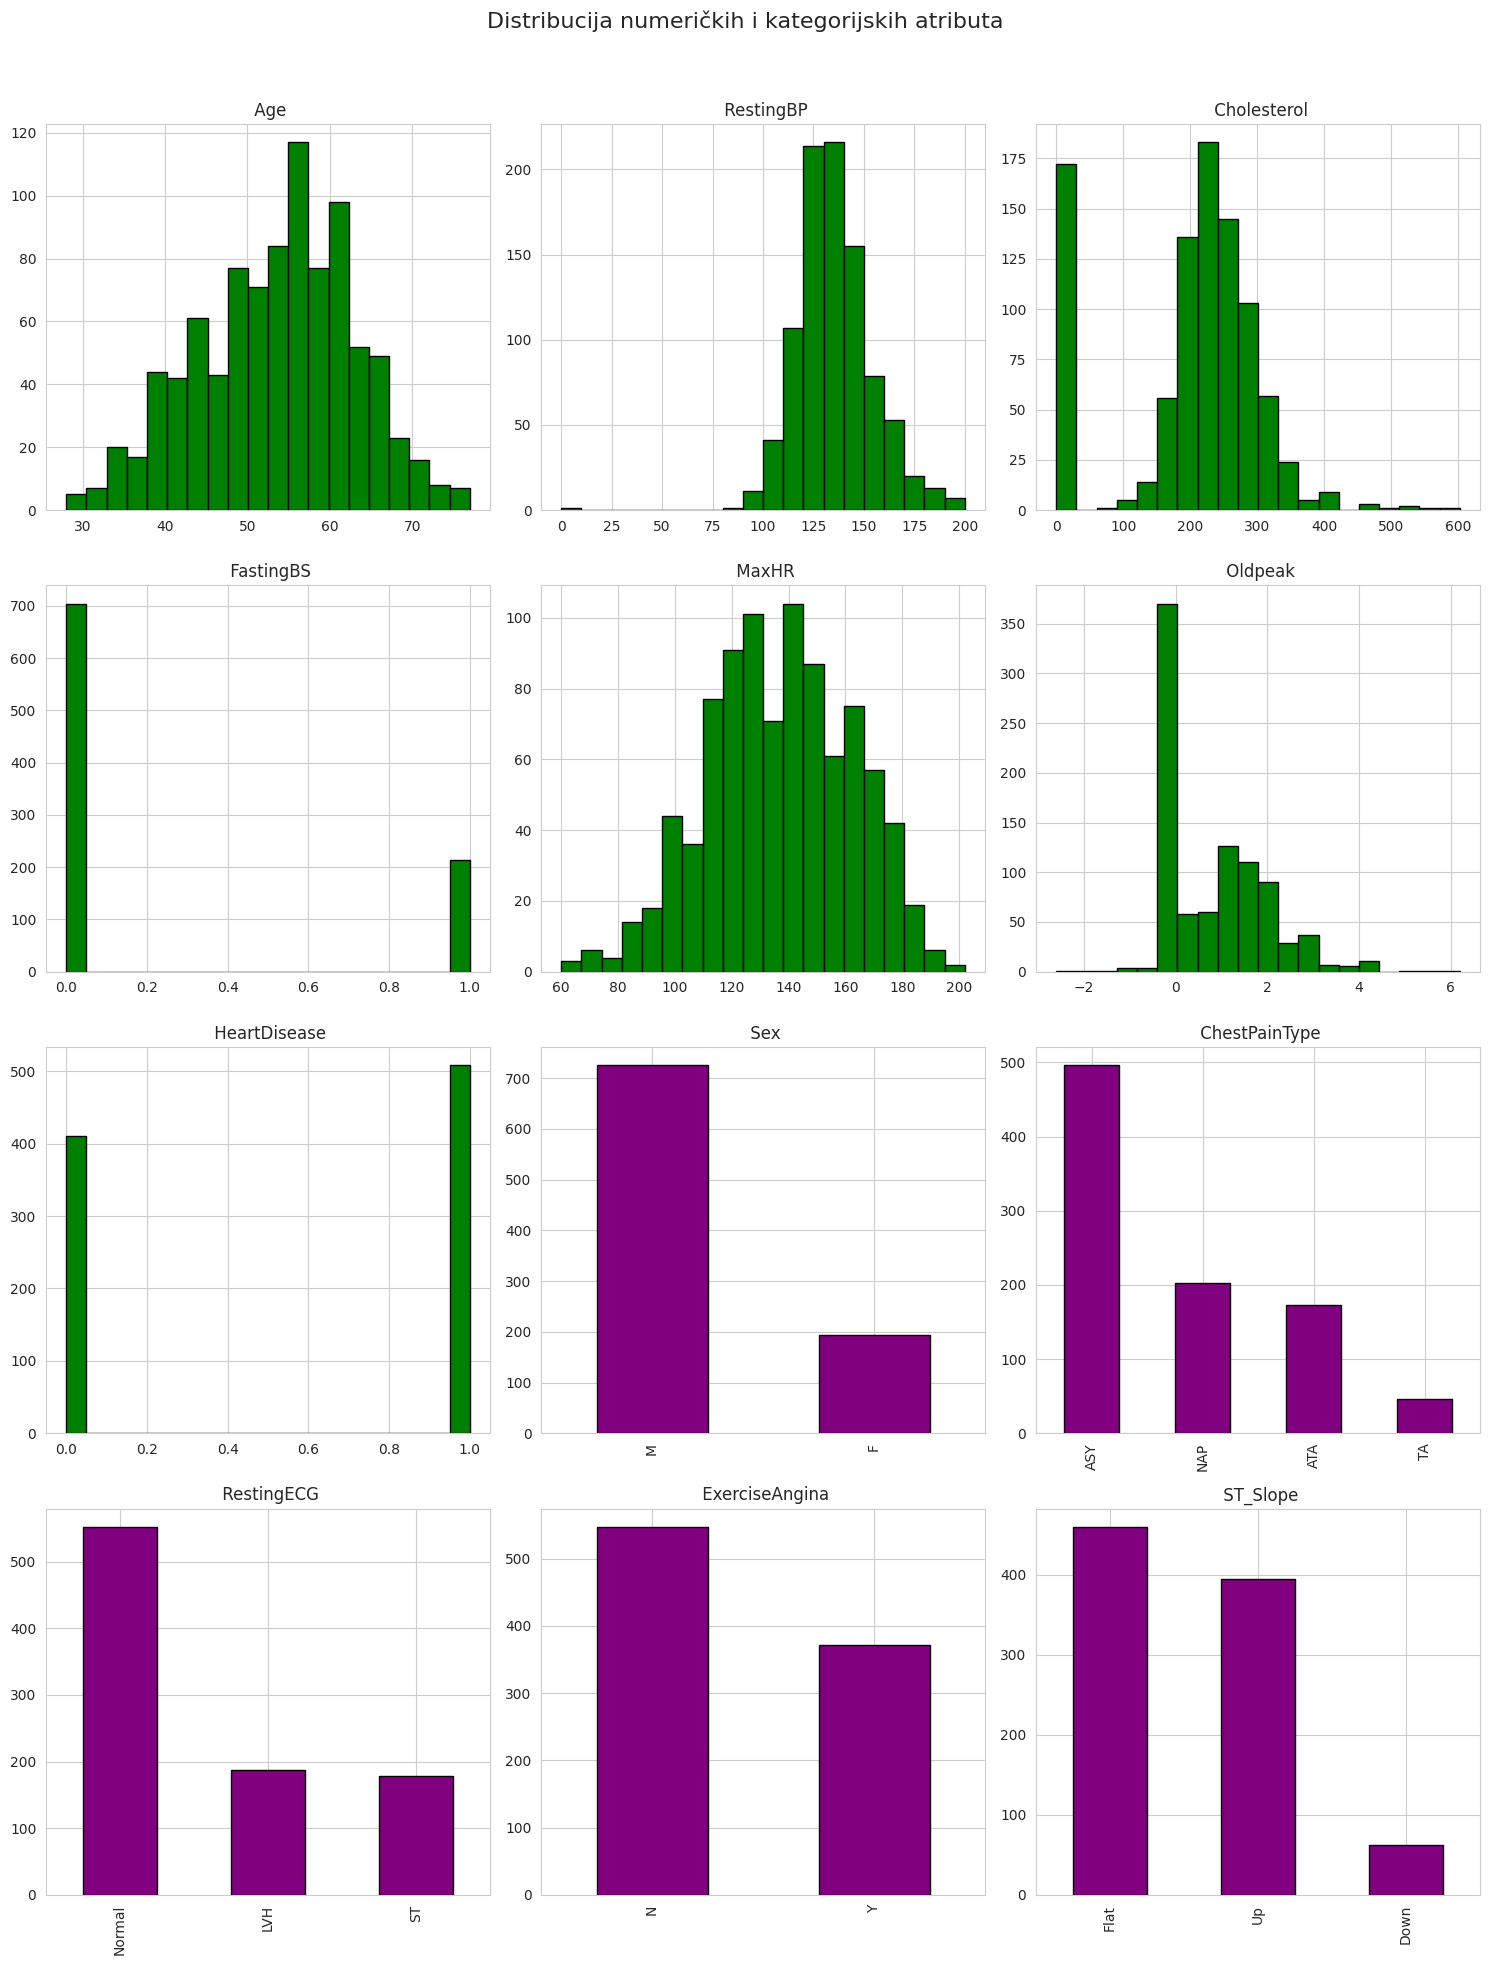

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")

df_numeric = df.select_dtypes(include=['int64', 'float64'])
df_categorical = df.select_dtypes(include=['object', 'string'])

num_numeric = len(df_numeric.columns)
num_categorical = len(df_categorical.columns)
total_plots = num_numeric + num_categorical

num_rows = int(np.ceil(total_plots / 3))
num_cols = min(3, total_plots)

fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(15, 5 * num_rows))
axes = axes.flatten()

for i, col in enumerate(df_numeric.columns):
    df_numeric[col].hist(ax=axes[i], bins=20, edgecolor='black', color='green')
    axes[i].set_title(f" {col}")

for j, col in enumerate(df_categorical.columns, start=num_numeric):
    df_categorical[col].value_counts().plot(kind='bar', ax=axes[j], color='purple', edgecolor='black')
    axes[j].set_title(f" {col}")
    axes[j].set_xlabel('')

for k in range(total_plots, len(axes)):
    fig.delaxes(axes[k])

plt.suptitle("Distribucija numeričkih i kategorijskih atributa", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()



Primer vizualizacije između dve kolone: ChestPainType i RestingECG. Cilj je prikazati kako se vrednosti za svaki od tih atributa distribuiraju u skupu podataka.

/tmp/ipython-input-11-1836892651.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='ChestPainType', palette='Set2', edgecolor='black')
/tmp/ipython-input-11-1836892651.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='RestingECG', palette='Set3', edgecolor='black')


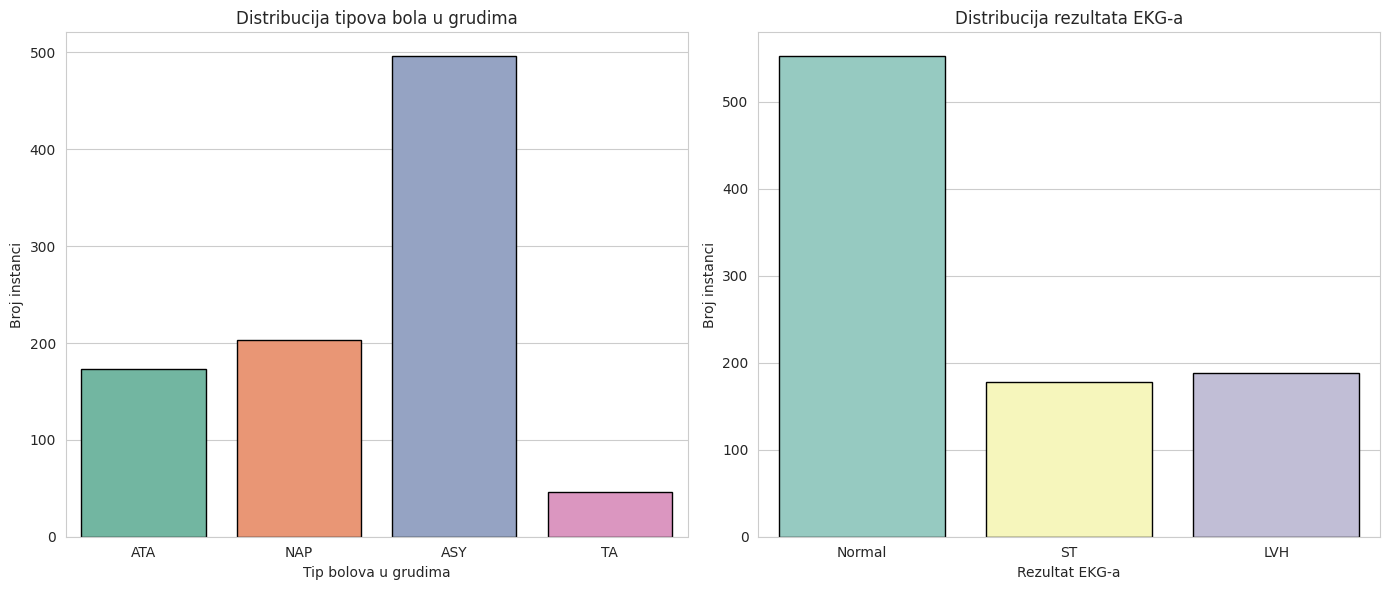

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='ChestPainType', palette='Set2', edgecolor='black')
plt.title('Distribucija tipova bola u grudima')
plt.xlabel('Tip bolova u grudima')
plt.ylabel('Broj instanci')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='RestingECG', palette='Set3', edgecolor='black')
plt.title('Distribucija rezultata EKG-a')
plt.xlabel('Rezultat EKG-a')
plt.ylabel('Broj instanci')

plt.tight_layout()
plt.show()

Boxplot prikaz autlajera – neobično visoke (ili niske) vrednosti holesterola koje mogu da utiču na treniranje modela.

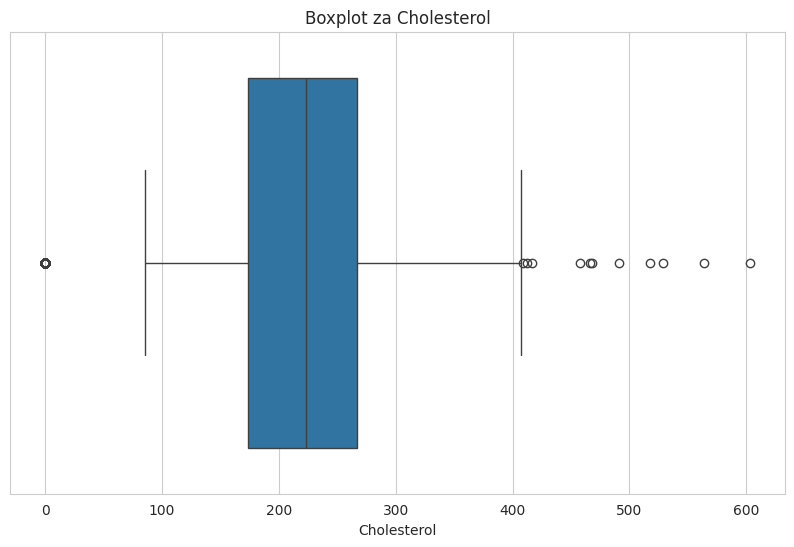

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df["Cholesterol"])
plt.title("Boxplot za Cholesterol")
plt.show()

Mreža scatter plot-ova koja koristi kolonu "Age" da boji tačke različitim nijansama u zavisnosti od vrednosti godina.

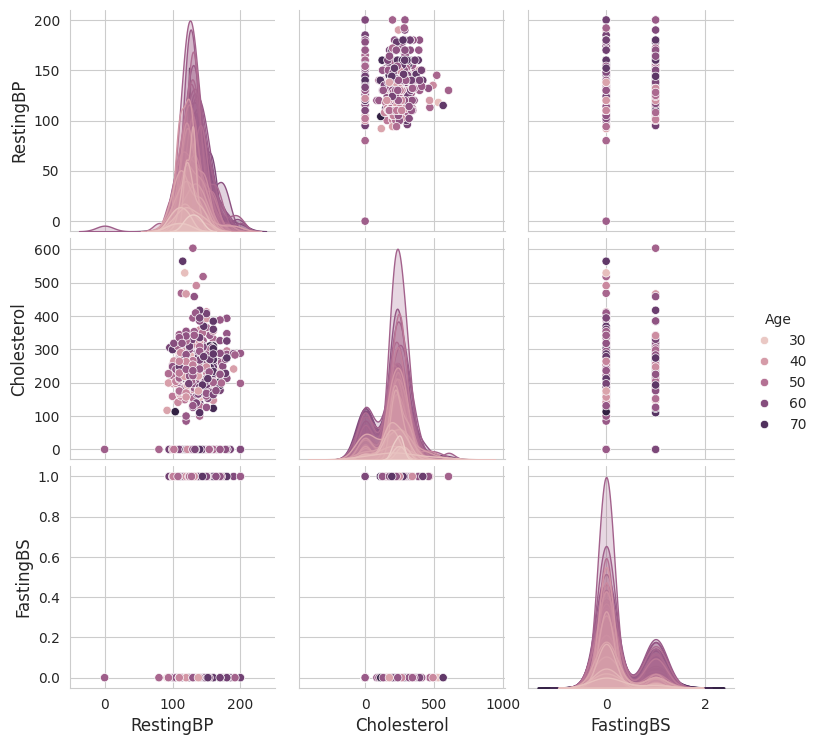

In [ ]:
g = sns.pairplot(df.iloc[:, 0:6], hue="Age")

for ax in g.axes.flatten():
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), fontsize=12)
        ax.set_ylabel(ax.get_ylabel(), fontsize=12)

plt.show()

# **4.  Opis izabranih metoda analize (pretprocesiranje, selekcija atributa, metodi učenja modela klasifikacije i regresije) i izbor njihove implementacije (programske biblioteke).**


---



*   Pretprocesiranje podataka - standardizacija numeričkih podataka.
*   Modeli učenja - Klasifikacija, Regresija.
*   Vizualizacija.




In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

#Definisanje numeričkih i kategorijskih kolona
num_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "FastingBS"]
cat_features = ["Sex", "ChestPainType", "RestingECG", "ST_Slope"]

#Kreiranje ColumnTransformer-a za obradu podataka
preprocessor = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)
    ]
)

#Definisanje ulaznih podataka X i ciljne promenljive y
X = df.drop(columns=["HeartDisease"])
y = df["HeartDisease"]


X_train_grid, X_test_grid, y_train_grid, y_test_grid = train_test_split(
    X, y, test_size=0.3, random_state=42
)

#Kreiranje pipeline-a koji uključuje preprocessing, selekciju karakteristika i model
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("feature_selection", SelectKBest(chi2, k=5)),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

#Definisanje Gradient Boosting i Random Forest
param_grid = [
    {   "feature_selection__k": [5, 6, 7],
        "classifier": [GradientBoostingClassifier(random_state=42)],
        "classifier__n_estimators": [50, 100, 200],
        "classifier__learning_rate": [0.01, 0.1, 0.2],
        "classifier__max_depth": [3, 4, 5]
    },
    {   "feature_selection__k": [5, 6, 7],
        "classifier": [RandomForestClassifier(random_state=42)],
        "classifier__n_estimators": [50, 100, 200],
        "classifier__max_depth": [None, 3, 5]
    }
]

#GridSearchCV
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=2)
grid_search.fit(X_train_grid, y_train_grid)

print("Najbolji CV skor:", grid_search.best_score_)

#Evaluacija na test skupu
y_pred_grid = grid_search.predict(X_test_grid)
accuracy_grid = accuracy_score(y_test_grid, y_pred_grid)
print("GridSearchCV Test Accuracy:", accuracy_grid)
print("GridSearchCV Classification Report:\n", classification_report(y_test_grid, y_pred_grid))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Najbolji CV skor: 0.8426356589147286
GridSearchCV Test Accuracy: 0.8586956521739131
GridSearchCV Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.89      0.84       112
           1       0.92      0.84      0.88       164

    accuracy                           0.86       276
   macro avg       0.85      0.86      0.86       276
weighted avg       0.87      0.86      0.86       276



##Treniranje modela na drugačiji način

In [ ]:
X_train_direct, X_test_direct, y_train_direct, y_test_direct = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#Primena transformacija na podatke
X_train_transformed = preprocessor.fit_transform(X_train_direct)
X_test_transformed = preprocessor.transform(X_test_direct)

print("X_train_transformed shape:", X_train_transformed.shape)
print("X_test_transformed shape:", X_test_transformed.shape)

#Treniranje Random Forest modela
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_transformed, y_train_direct)

#Predikcija i evaluacija
y_pred_rf = rf_model.predict(X_test_transformed)
accuracy_rf = accuracy_score(y_test_direct, y_pred_rf)
print("Random Forest Test Accuracy:", accuracy_rf)
print("Random Forest Classification Report:\n", classification_report(y_test_direct, y_pred_rf))

X_train_transformed shape: (734, 18)
X_test_transformed shape: (184, 18)
Random Forest Test Accuracy: 0.8695652173913043
Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.87      0.86        82
           1       0.89      0.87      0.88       102

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184



In [ ]:
X_train_direct, X_test_direct, y_train_direct, y_test_direct = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#Primena transformacija na podatke
X_train_transformed = preprocessor.fit_transform(X_train_direct)
X_test_transformed = preprocessor.transform(X_test_direct)

print("X_train_transformed shape:", X_train_transformed.shape)
print("X_test_transformed shape:", X_test_transformed.shape)

#Treniranje Logistic Regression modela
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_transformed, y_train_direct)

#Predikcija i evaluacija
y_pred_lr = lr_model.predict(X_test_transformed)
accuracy_lr = accuracy_score(y_test_direct, y_pred_lr)
print("Logistic Regression Test Accuracy:", accuracy_lr)
print("Logistic Regression Classification Report:\n", classification_report(y_test_direct, y_pred_lr))

X_train_transformed shape: (734, 18)
X_test_transformed shape: (184, 18)
Logistic Regression Test Accuracy: 0.8586956521739131
Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.80      0.84        82
           1       0.85      0.90      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86      0.86      0.86       184



# **5. Objašnjiva veštačka inteligencija**

---
U cilju bolje interpretacije modela i razumevanja njegovih odluka, primenjena je metoda SHAP (SHapley Additive exPlanations), koja omogućava analizu uticaja pojedinačnih atributa na krajnju predikciju modela.

Korišćen je Random Forest model koji je prethodno pokazao dobre performanse. SHAP analiza omogućava da se vizuelno prikaže koji atributi najviše doprinose donošenju odluka.

Summary plot daje pregled najznačajnijih osobina koje utiču na klasifikaciju prisustva srčane bolesti, što pomaže u tumačenju ponašanja modela i potencijalnom medicinskom zaključivanju.


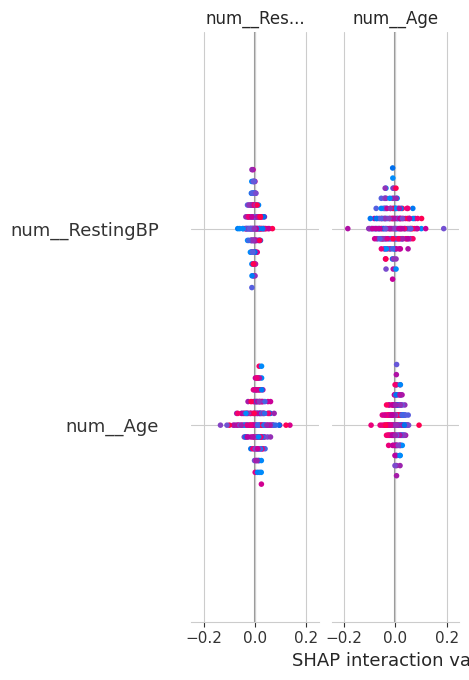

In [ ]:
#Analiza uticaja atributa korišćenjem SHAP biblioteke
import shap
shap.initjs()
explainer = shap.Explainer(rf_model, feature_names=preprocessor.get_feature_names_out())

#Konvertujemo test skup u DataFrame sa imenima kolona
X_test_df = pd.DataFrame(X_test_transformed, columns=preprocessor.get_feature_names_out())

#Izračunavanje SHAP vrednosti
shap_values = explainer(X_test_df)

#Summary plot svih SHAP vrednosti
shap.summary_plot(shap_values, X_test_df)
